# Single Layer Perceptron (SLP) — Binary Classification of Iris Data

**Assignment 1 — Single Layer Perceptron**
Rifda Faticha Alfa Aziza

Binary classification of the Iris dataset: **Iris-setosa = 0**, **Iris-versicolor = 1**,
using four features (sepal length, sepal width, petal length, petal width).

The SLP is implemented **from scratch in pure Python, without any library**, and follows exactly
the same steps as the Google Sheet. `matplotlib` is used **only** in the last section to draw the charts.

| Setting | Value |
|---|---|
| Training data | 80 rows (first 40 setosa + first 40 versicolor) |
| Validation data | 20 rows (last 10 setosa + last 10 versicolor) |
| Initial bias & teta1–teta4 | 0.5 |
| Learning rate | 0.1 |
| Epochs | 5 |

## 1. Formulas (same as the Google Sheet)

- Dot product: $z = bias + \theta_1 x_1 + \theta_2 x_2 + \theta_3 x_3 + \theta_4 x_4$
- Sigmoid: $g(z) = \dfrac{1}{1 + e^{-z}}$
- Prediction: $1$ if $g(z) > 0.5$, else $0$
- Error: $g(z) - target$, Sum Square Error: $(g(z) - target)^2$
- Gradient: $d\theta_i = 2\,(g(z) - target)\,(1 - g(z))\,g(z)\,x_i$  (with $x = 1$ for the bias)
- Update after every row: $\theta_i \leftarrow \theta_i - \alpha \cdot d\theta_i$
- Loss per epoch = average SSE; Accuracy per epoch = correct predictions / number of rows
- Validation uses the bias and teta obtained at the end of each training epoch.

## 2. Hyper-parameters

In [1]:
E = 2.718281828459045   # Euler's number, written manually so no math library is needed

LEARNING_RATE = 0.1
EPOCHS = 5
INITIAL_WEIGHT = 0.5     # bias, teta1, teta2, teta3, teta4 all start at 0.5
DATA_FILE = "iris_binary.csv"

## 3. Load the data and split training / validation

In [2]:
def load_data(path):
    setosa, versicolor = [], []
    with open(path) as f:
        lines = f.read().strip().split("\n")[1:]   # skip header
    for line in lines:
        parts = line.split(",")
        x = [float(v) for v in parts[:4]]
        if parts[4] == "Iris-setosa":
            setosa.append((x, 0))
        elif parts[4] == "Iris-versicolor":
            versicolor.append((x, 1))
    return setosa, versicolor


setosa, versicolor = load_data(DATA_FILE)
train_data = setosa[:40] + versicolor[:40]
val_data = setosa[40:50] + versicolor[40:50]

print("Total data      :", len(setosa) + len(versicolor))
print("Training data   :", len(train_data))
print("Validation data :", len(val_data))
print("First training row:", train_data[0])

Total data      : 100
Training data   : 80
Validation data : 20
First training row: ([5.1, 3.5, 1.4, 0.2], 0)


## 4. SLP functions (no library)

In [3]:
def sigmoid(z):
    return 1 / (1 + E ** (-z))


def predict(g):
    return 1 if g > 0.5 else 0


def dot_product(weights, x):
    # weights = [bias, teta1, teta2, teta3, teta4], x = [x1, x2, x3, x4]
    z = weights[0]
    for i in range(len(x)):
        z += weights[i + 1] * x[i]
    return z


def train_one_epoch(data, weights, lr):
    total_sse, correct = 0.0, 0
    for x, target in data:
        z = dot_product(weights, x)
        g = sigmoid(z)
        error = g - target
        total_sse += error ** 2
        if predict(g) == target:
            correct += 1

        # gradient of (g - target)^2 with respect to bias and each teta
        common = 2 * (g - target) * (1 - g) * g
        grads = [common] + [common * xi for xi in x]

        # update the weights for the next row
        weights = [w - lr * d for w, d in zip(weights, grads)]

    loss = total_sse / len(data)
    accuracy = correct / len(data) * 100
    return weights, loss, accuracy


def evaluate(data, weights):
    total_sse, correct = 0.0, 0
    for x, target in data:
        g = sigmoid(dot_product(weights, x))
        total_sse += (g - target) ** 2
        if predict(g) == target:
            correct += 1
    return total_sse / len(data), correct / len(data) * 100

## 5. Training and validation for 5 epochs

In [4]:
weights = [INITIAL_WEIGHT] * 5
history = []   # (epoch, train_loss, train_acc, val_loss, val_acc)

print("Epoch | Train Loss | Train Acc (%) | Val Loss   | Val Acc (%)")
print("-" * 62)
for epoch in range(1, EPOCHS + 1):
    weights, train_loss, train_acc = train_one_epoch(train_data, weights, LEARNING_RATE)
    val_loss, val_acc = evaluate(val_data, weights)
    history.append((epoch, train_loss, train_acc, val_loss, val_acc))
    print("%5d | %10.6f | %13.2f | %10.6f | %11.2f"
          % (epoch, train_loss, train_acc, val_loss, val_acc))

print("\nFinal weights:")
for name, w in zip(["bias", "teta1", "teta2", "teta3", "teta4"], weights):
    print("  %-6s = %.6f" % (name, w))

Epoch | Train Loss | Train Acc (%) | Val Loss   | Val Acc (%)
--------------------------------------------------------------
    1 |   0.449889 |         52.50 |   0.328951 |       50.00
    2 |   0.037452 |         95.00 |   0.247289 |       50.00
    3 |   0.024372 |         97.50 |   0.175892 |       50.00
    4 |   0.017357 |         97.50 |   0.119381 |       85.00
    5 |   0.012740 |         98.75 |   0.081581 |      100.00

Final weights:
  bias   = 0.257720
  teta1  = -0.241802
  teta2  = -0.416903
  teta3  = 1.122214
  teta4  = 0.824059


## 6. Save the results per epoch

In [5]:
with open("results.csv", "w") as f:
    f.write("epoch,train_loss,train_accuracy,val_loss,val_accuracy\n")
    for row in history:
        f.write("%d,%.10f,%.4f,%.10f,%.4f\n" % row)
print("Saved to results.csv")

Saved to results.csv


## 7. Accuracy and loss charts

`matplotlib` is used **only here, for plotting**. The SLP above does not use any library.

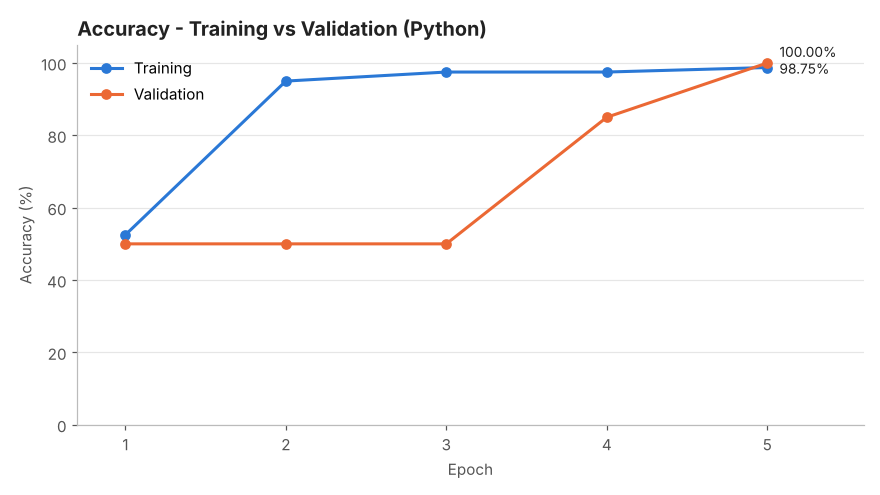

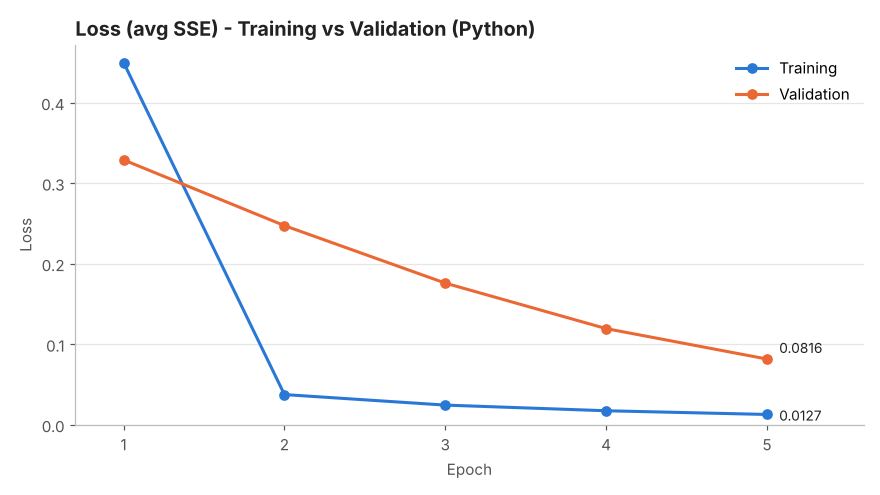

In [6]:
import matplotlib.pyplot as plt

TRAIN_COLOR = "#2a78d6"
VAL_COLOR = "#eb6834"

epochs = [h[0] for h in history]
tr_loss = [h[1] for h in history]
tr_acc = [h[2] for h in history]
va_loss = [h[3] for h in history]
va_acc = [h[4] for h in history]


def draw(ytr, yva, title, ylabel, fname, fmt, ylim=None):
    fig, ax = plt.subplots(figsize=(8, 4.5), dpi=110)
    ax.plot(epochs, ytr, color=TRAIN_COLOR, linewidth=2, marker="o", markersize=6, label="Training")
    ax.plot(epochs, yva, color=VAL_COLOR, linewidth=2, marker="o", markersize=6, label="Validation")
    if ylim:
        ax.set_ylim(*ylim)
    # label only the final values to keep the chart clean
    ax.annotate(fmt % ytr[-1], (epochs[-1], ytr[-1]), textcoords="offset points",
                xytext=(8, -4), color="#222222", fontsize=9)
    ax.annotate(fmt % yva[-1], (epochs[-1], yva[-1]), textcoords="offset points",
                xytext=(8, 4), color="#222222", fontsize=9)
    ax.set_xlim(0.7, epochs[-1] + 0.6)
    ax.set_title(title, fontsize=13, fontweight="bold", loc="left", color="#222222")
    ax.set_xlabel("Epoch", color="#555555")
    ax.set_ylabel(ylabel, color="#555555")
    ax.set_xticks(epochs)
    ax.grid(axis="y", color="#e6e6e6", linewidth=0.8)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color("#bbbbbb")
    ax.tick_params(colors="#555555")
    ax.legend(frameon=False, loc="best")
    fig.tight_layout()
    fig.savefig(fname, dpi=200)
    plt.show()


draw(tr_acc, va_acc, "Accuracy - Training vs Validation (Python)", "Accuracy (%)",
     "accuracy_chart.png", "%.2f%%", ylim=(0, 105))
draw(tr_loss, va_loss, "Loss (avg SSE) - Training vs Validation (Python)", "Loss",
     "loss_chart.png", "%.4f", ylim=(0, None))